# 06 客户价值与留存（MySQL + Python 可视化）

**数据源**：MySQL `olist`（`v_order_base`）
**分析逻辑**：执行 `analysis_code/06_customer_value.sql`（4 条查询）
**口径**：客户价值类指标只取**已送达**订单；「首单体验 → 复购」是**相关性**，不是因果。


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 找到项目根（含 analysis_code/ 的目录），兼容从 notebooks/ 或项目根启动
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_code").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks"))
import db

# 先设 seaborn 主题，再设中文字体（顺序不能反）
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

print("project root:", PROJECT_ROOT)
print("sql dir:", db.SQL_DIR)

project root: C:\Users\iiLI\Desktop\1
sql dir: C:\Users\iiLI\Desktop\1\analysis_code


## 1. 执行 SQL

In [2]:
results = db.run_sql_file(db.SQL_DIR / "06_customer_value.sql")
buy, rfm, geo, late = results

for name, df in zip(["buy", "rfm", "geo", "late"], results):
    print(f"{name:6s} {df.shape}")

buy

buy    (9, 3)
rfm    (5, 4)
geo    (27, 4)
late   (3, 4)


,buy_times,customer_count,repeat_rate_pct
0,1,90315,97.00
1,2,2562,2.75
2,3,180,0.19
3,4,28,0.03
4,5,9,0.01
5,6,5,0.01
6,7,3,0.00
7,9,1,0.00
8,15,1,0.00


## 2. 图 1：购买频次分布与复购率

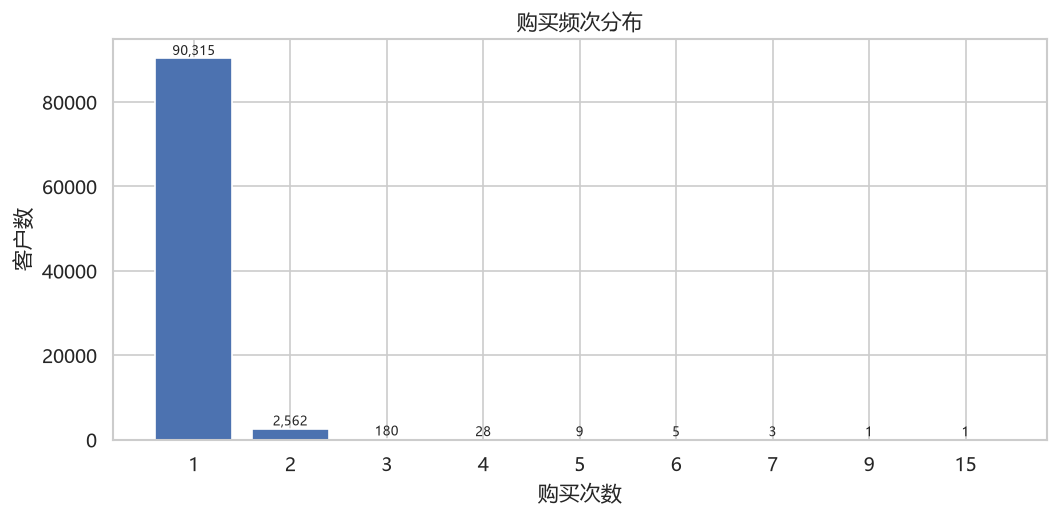

总客户数            : 93,104
复购客户数(>=2 次)  : 2,789
复购率              : 3.00%


In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(buy["buy_times"].astype(str), buy["customer_count"], color="#4C72B0")
ax.set_xlabel("购买次数")
ax.set_ylabel("客户数")
ax.set_title("购买频次分布")
for bar, v in zip(ax.patches, buy["customer_count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"{int(v):,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

total_customers = buy["customer_count"].sum()
repeat_customers = buy.loc[buy["buy_times"] > 1, "customer_count"].sum()
print(f"总客户数            : {int(total_customers):,}")
print(f"复购客户数(>=2 次)  : {int(repeat_customers):,}")
print(f"复购率              : {100 * repeat_customers / total_customers:.2f}%")

### 观察
- 买 1 次的客户大约占97%，平台粘性极差，仅有3%的人进行了复购
- 复购率低说明：用户生命周期短，缺乏生态粘性。
- 对拉新/留存的策略：优化首单体验；寻找高意向，高复购潜力的人群


## 3. 图 2：RFM 客户分层

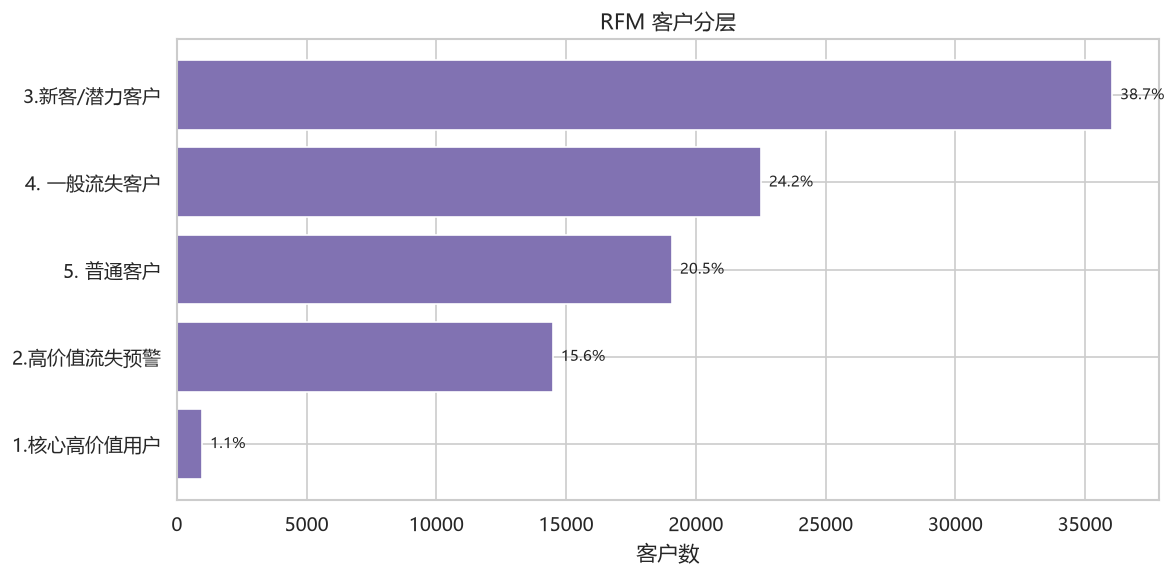

In [4]:
rfm_sorted = rfm.sort_values("customer_cnt")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(rfm_sorted["customer_segment"], rfm_sorted["customer_cnt"], color="#8172B2")
ax.set_xlabel("客户数")
ax.set_title("RFM 客户分层")
for bar, pct in zip(ax.patches, rfm_sorted["pct_of_total"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {pct:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.show()

### 观察
- 核心高价值用户仅占1.1%
- 「高价值流失预警」规模大，要对这些用户进行换回，推送优惠劵等措施。


## 4. 图 3：Top 10 州：客户数与人均 GMV

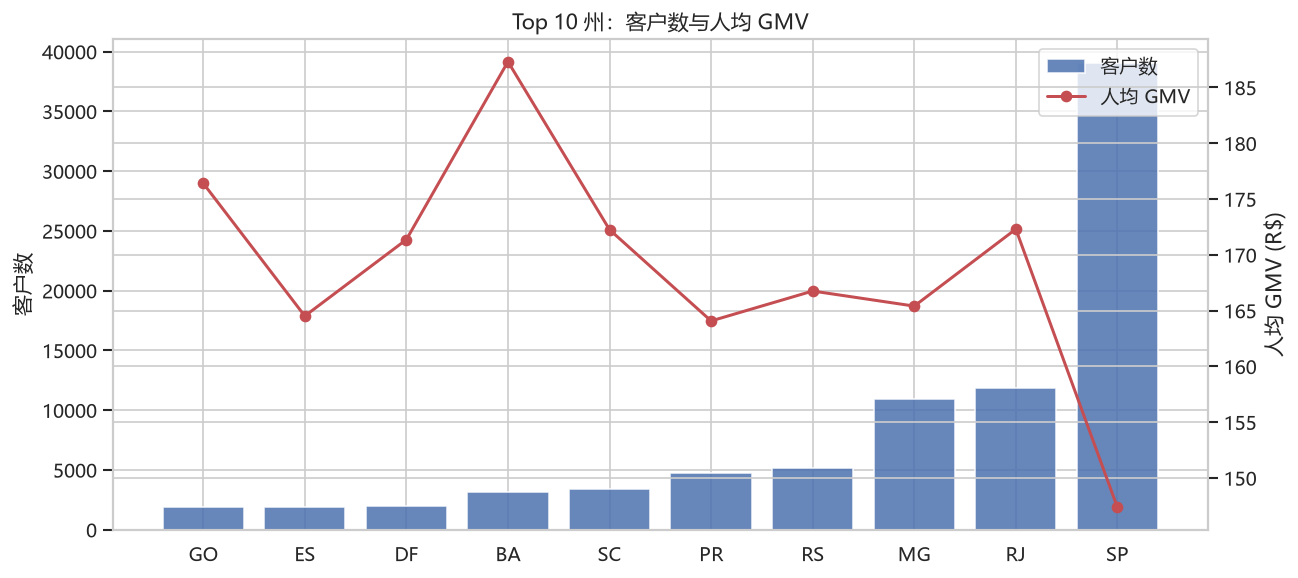

In [5]:
g = geo.nlargest(10, "total_customers").sort_values("total_customers")

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(g["customer_state"], g["total_customers"], color="#4C72B0", alpha=0.85, label="客户数")
ax.set_ylabel("客户数")
ax2 = ax.twinx()
ax2.plot(g["customer_state"], g["gmv_per_customer"], color="#C44E52", marker="o", lw=1.8, label="人均 GMV")
ax2.set_ylabel("人均 GMV (R$)")
ax.set_title("Top 10 州：客户数与人均 GMV")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")
plt.tight_layout()
plt.show()

### 观察
- 客户最多的州是人均 GMV 最低的州，说明人数多，物流基建好，商家竞争激烈。


## 5. 图 4：首单配送状态 vs 复购率

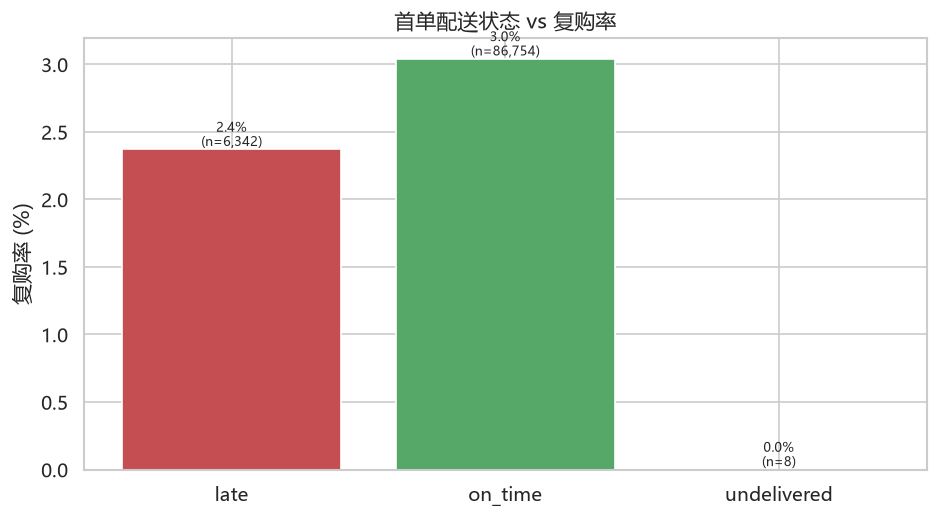

,first_order_status,total_customers,repeat_customers,repeat_rate_pct
0,late,6342,150.0,2.37
1,on_time,86754,2639.0,3.04
2,undelivered,8,0.0,0.00


In [6]:
late = late.copy()
color_map = {"on_time": "#55A868", "late": "#C44E52", "undelivered": "#999999"}
colors = [color_map.get(s, "#4C72B0") for s in late["first_order_status"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(late["first_order_status"], late["repeat_rate_pct"], color=colors)
ax.set_ylabel("复购率 (%)")
ax.set_title("首单配送状态 vs 复购率")
for bar, n, r in zip(ax.patches, late["total_customers"], late["repeat_rate_pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, r, f"{r:.1f}%\n(n={int(n):,})",
            ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

late[["first_order_status", "total_customers", "repeat_customers", "repeat_rate_pct"]]

### 观察
- 首单迟到的客户复购率显著低于首单及时的客户复购率。
- 迟达不仅流失用户，还制造了高危用户。
- 策略：建立迟达补偿机制；
- **重要**：这是相关性，不是因果。迟到客户可能本身在偏远地区、订单更复杂，存在混杂因素。
